In [2]:
%pip install numpy
%pip install matplotlib
%pip install pandas
%pip install scipy
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [3]:
cols = [
    "burst",        # Burst counter
    "ensemble",     # Ensemble counter (1-65536)
    "w",            # Velocity Beam1|X|East (m/s) orginally u renamed to w to reflect vertical velocities
    "u",            # Velocity Beam2|Y|North (m/s) originally v now renamed to u to reflect crossh shore velocities
    "v",            # Velocity Beam3|Z|Up (m/s) orginally w now renamed to v to reflect alongshore velocities
    "amp1",         # Amplitude Beam1 (counts)
    "amp2",         # Amplitude Beam2 (counts)
    "amp3",         # Amplitude Beam3 (counts)
    "snr1",         # SNR Beam1 (dB)
    "snr2",         # SNR Beam2 (dB)
    "snr3",         # SNR Beam3 (dB)
    "corr1",        # Correlation Beam1 (%)
    "corr2",        # Correlation Beam2 (%)
    "corr3",        # Correlation Beam3 (%)
    "pressure",     # Pressure (dbar)
    "analog1",      # Analog input 1
    "analog2",      # Analog input 2
    "checksum",     # Checksum (1 = failed)
]

df_SSC01 = pd.read_csv("SSC01.dat", sep=r"\s+", header=None, names=cols)
df_SSC02L = pd.read_csv("SSC02A.dat", sep=r"\s+", header=None, names=cols)
df_SSC02H = pd.read_csv("SSC02B.dat", sep=r"\s+", header=None, names=cols)

In [4]:
df_SSC01["t"] = df_SSC01.index / 16                     #Data from first field compain on 29 september
start = pd.Timestamp("2026-09-29 06:00:00")
df_SSC01["time"] = start + pd.to_timedelta(df_SSC01["t"], unit="s")

df_SSC02L["t"] = df_SSC02L.index / 16.                  #Data from second field compain on 2 oktober from the lowest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02L["time"] = start + pd.to_timedelta(df_SSC02L["t"], unit="s")

df_SSC02H["t"] = df_SSC02H.index / 16                   #Data from second field compain on 2 oktober from the highest sensor
start = pd.Timestamp("2026-10-02 06:00:00")
df_SSC02H["time"] = start + pd.to_timedelta(df_SSC02H["t"], unit="s")

In [5]:
m = pd.read_csv("manoeuvresTimes.csv") #import of the manoeuvres times
manoeuvres = {k: v.split(";") for k, v in zip(m["id"], m["times"])}

def select(ids):
    """Accepts one id ("B-11"), a list (["B-11", "B-12"]) or a whole type ("B")."""
    if isinstance(ids, str):
        ids = [ids]
    out = []
    for i in ids:
        if i in manoeuvres:
            out.append(i)
        else:
            matches = [k for k in manoeuvres if k.split("-")[0] == i]
            if not matches:
                raise KeyError(f"Unknown manoeuvre or type: {i}")
            out += matches
    return out

def sources(name, sensor="Both"):
    """Which dataframe(s) to use for a manoeuvre, from its series digit (the 3 in B-31)."""
    if name[-2] in "1234":
        return [(df_SSC01, "", "-")]
    out = []
    if sensor in ("Both", "Low"):
        out.append((df_SSC02L, "Low", "-."))
    if sensor in ("Both", "High"):
        out.append((df_SSC02H, "High", "--"))
    return out

def plot_overlay(ids, sensor="Both", before=120, after=120, col="analog1"):
    fig, ax = plt.subplots(figsize=(10, 5))

    for name in select(ids):
        t = manoeuvres[name]
        if isinstance(t, str):              # single pass -> list of one
            t = [t]
        offsets = pd.to_timedelta(t)        # time of day of each pass

        for data, suffix, ls in sources(name, sensor):
            times = data["time"].iloc[0].normalize() + offsets
            c = times[0]
            win = data[(data["time"] >= c - pd.Timedelta(seconds=before)) &
                       (data["time"] <= times[-1] + pd.Timedelta(seconds=after))]
            if win.empty:
                print(f"No data around {name}{suffix} ({c:%H:%M:%S}), skipped")
                continue
            rel_t = (win["time"] - c).dt.total_seconds()
            ax.plot(rel_t, win[col], ls=ls, lw=0.8, label=f"{name}{suffix}  ({c:%H:%M:%S})")

        if len(t) > 1:                      # F manoeuvres: mark every pass
            for i, off in enumerate(offsets, 1):
                x = (off - offsets[0]).total_seconds()
                ax.axvline(x, color="k", ls="--", lw=0.8)
                ax.text(x, 0.95, f"pass {i}", transform=ax.get_xaxis_transform(),
                        ha="center", fontsize=10, color="red",
                        bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="k"))

    ax.axvline(0, color="k", ls="--", lw=0.8)
    ax.set_xlabel("Time relative to boat passage (s)")
    ax.set_ylabel(col)
    ax.set_title(f"{col}: {before} s before to {after} s after passage")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

#### Plotting manoeuvres with `plot_overlay`
`plot_overlay` plots the sensor signal around one or more boat passages, with time shown relative to the moment of passage.

```python
plot_overlay("B-21", before=120, after=120, col="w")   # one manoeuvre
plot_overlay(["B-11", "B-12"], col="analog1")          # a few manoeuvres
plot_overlay("B", col="analog1")                       # every B manoeuvre
```
| Argument | What it does | Default |
|---|---|---|
| `before` | Seconds to plot before the manoeuvre | `120` |
| `after` | Seconds to plot after the manoeuvre | `120` |
| `col` | Column to plot, e.g. `"analog1"`, `"u"`, `"v"`, `"w"`, `"pressure"` | `"analog1"` |
| `sensor` | Which sensor to use for the second field day (see below) | `"Both"` |


This only applies to data from the second field day (2 October).
- `sensor="Both"` → plots both the high and the low sensor
- `sensor="Low"` → plots only the low sensor
- `sensor="High"` → plots only the high sensor

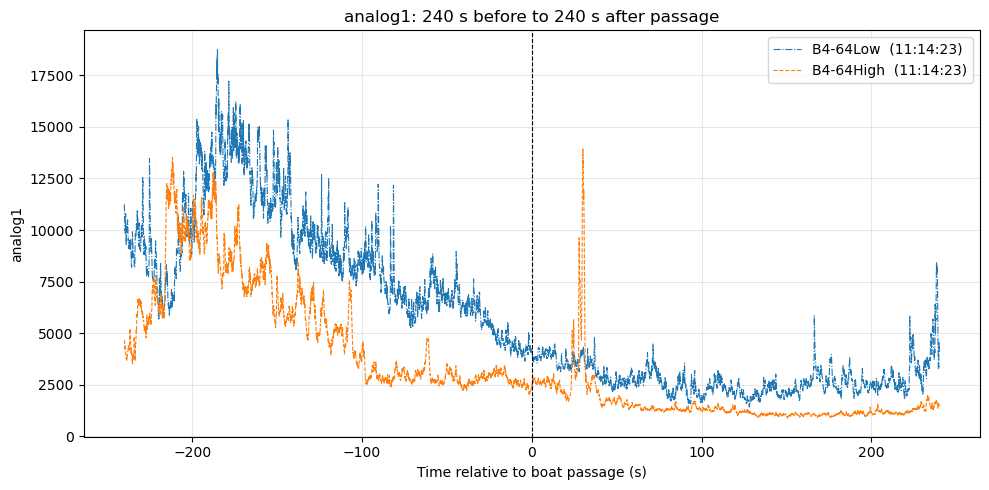

In [27]:
plot_overlay("F-71", before = 240, after = 240, col = "v")                       # one manoeuvre

#plot_overlay(df, "B-21", before = 1000, after = 1000, col = "v")    
#plot_overlay(df, "B-21", before = 120, after = 120, col = "w")                       # one manoeuvre
                   # one manoeuvre
#plot_overlay(df, ["B-11", "B-12"], col="analog")    # a few
#plot_overlay(df, "B", col="analog1")                 # every B manoeuvre
#plot_overlay(df, "A1")                         # every A1 manoeuvre

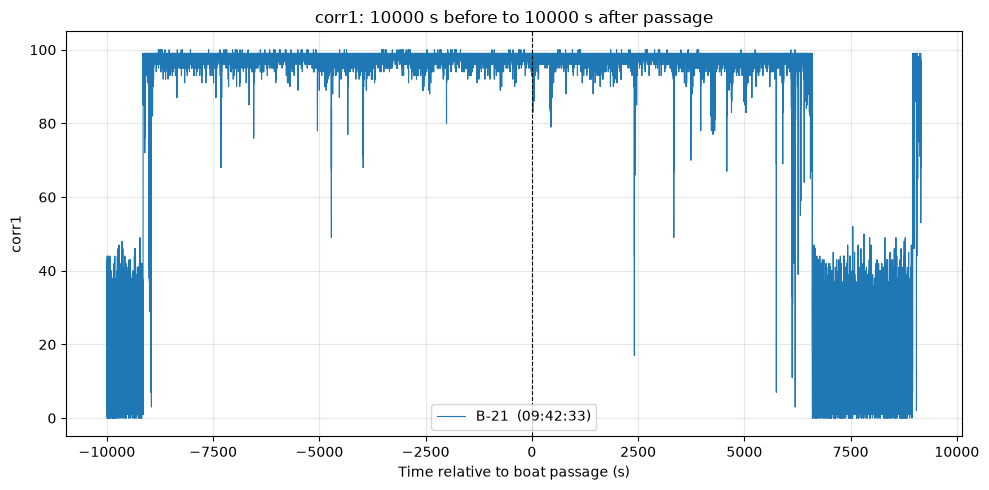

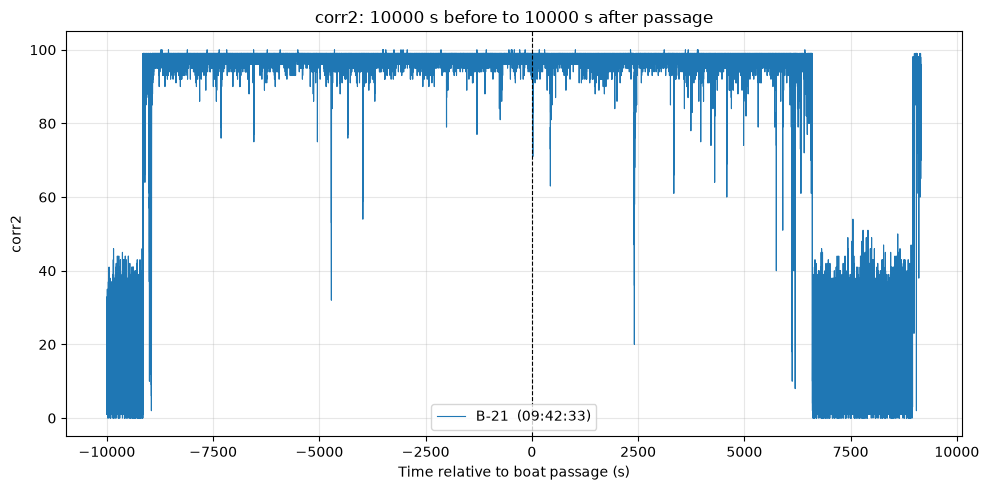

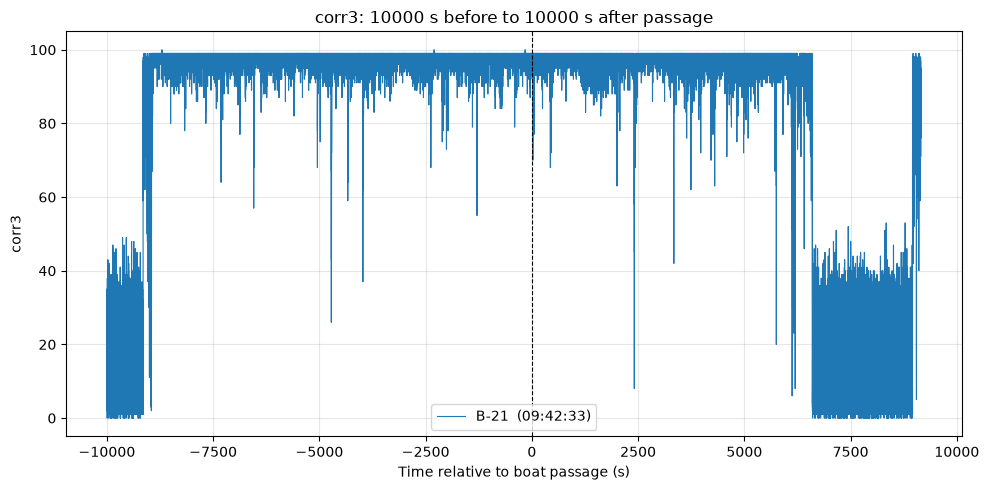

In [10]:
plot_overlay("B-21", before = 10000, after = 10000, col = "corr1")
plot_overlay("B-21", before = 10000, after = 10000, col = "corr2")
plot_overlay("B-21", before = 10000, after = 10000, col = "corr3")                       # one manoeuvre
                       # one manoeuvre
                       # one manoeuvre


### Pressure Sensor Data

In [7]:
# print(df['pressure']) 
# print(df['time'])

In [19]:
# SSC01 pressure is sampled at 16 Hz; tidalinfo2909 contains lower-frequency
# atmospheric pressure and water-level observations.
pressure = df_SSC01[["time", "pressure"]].copy()
pressure["time"] = pd.to_datetime(pressure["time"])

tidalinfo2909 = pd.read_csv("1762026_aligned.csv")
tidalinfo2909["datetime"] = pd.to_datetime(tidalinfo2909["datetime"])
tidalinfo2909["Pressure_air"] = pd.to_numeric(
    tidalinfo2909["Pressure_air"], errors="coerce"
)
air_pressure = (
    tidalinfo2909.dropna(subset=["datetime", "Pressure_air"])
    .assign(datetime=lambda frame: frame["datetime"].dt.floor("min"))
    .groupby("datetime", as_index=False)["Pressure_air"]
    .median()
    .rename(columns={"datetime": "time"})
    .sort_values("time")
)

# Match by time rather than row number; the tolerance prevents distant joins.
pressure = pd.merge_asof(
    pressure.sort_values("time"),
    air_pressure,
    on="time",
    direction="nearest",
    tolerance=pd.Timedelta("90s"),
)
if pressure["Pressure_air"].isna().any():
    missing_fraction = pressure["Pressure_air"].isna().mean()
    raise ValueError(
        f"Atmospheric pressure is missing for {missing_fraction:.1%} of SSC samples; "
        "check the logger time ranges before continuing."
    )

# Pressure_air is in hPa; 1 dbar is approximately 1 hPa.
pressure["air_pressure_dbar"] = pressure["Pressure_air"] / 100.0

display(pressure[["time", "pressure", "Pressure_air", "air_pressure_dbar"]].head())
# display(tidalinfo2909)

,time,pressure,Pressure_air,air_pressure_dbar
0,2026-09-29 06:00:00.000000,0.212,1013.27,10.1327
1,2026-09-29 06:00:00.062500,0.211,1013.27,10.1327
2,2026-09-29 06:00:00.125000,0.214,1013.27,10.1327
3,2026-09-29 06:00:00.187500,0.211,1013.27,10.1327
4,2026-09-29 06:00:00.250000,0.214,1013.27,10.1327


In [9]:
pressure["time"] = pd.to_datetime(pressure["time"])

target_start = pd.Timestamp("2026-09-29 07:30:00")
result_start = pressure.loc[pressure["time"].eq(target_start)]
# print(result_start)

target_end = pd.Timestamp("2026-09-29 11:25:00")
result_end = pressure.loc[pressure["time"].eq(target_end)]
# print(result_end)

/var/folders/3q/ddmvnbcj1f790651pr18mj9r0000gn/T/ipykernel_2366/4129958430.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pressure["time"] = pd.to_datetime(pressure["time"])


Text(0.5, 1.0, 'Pressure Timesiers')

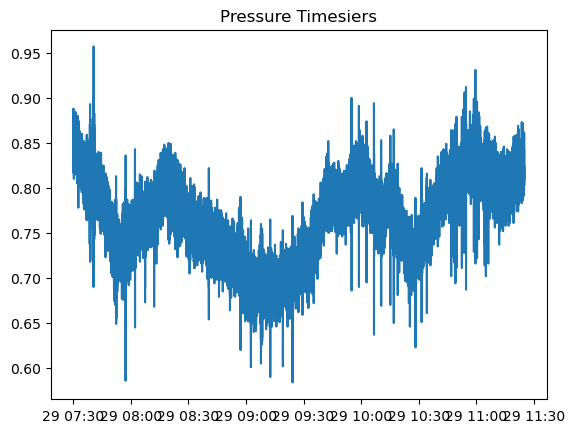

In [10]:
# df['pressure'].plot()
plt.plot(pressure['time'][86400:312000], pressure['pressure'][86400:312000]);
plt.title('Pressure Timesiers')

In [11]:
sampling_rate = 16              # Hz
sensor_height = 0.395 + 0.06   # m above the bed
rho = 1025                      # density of seawater in kg/m^3
g = 9.81                        # acceleration due to gravity in m/s^2

# Remove atmospheric pressure so the depth is based on water pressure only.
pressure["pressure_water"] = pressure["pressure"] - pressure["air_pressure_dbar"]
press_pa = pressure["pressure_water"] * 1e4  # dbar to Pa
depth = press_pa / (rho * g) + sensor_height

In [12]:
from scipy.signal import butter, sosfiltfilt

def signals_filter(data, cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    sos = butter(order, normal_cutoff, btype="low", output="sos")
    return sosfiltfilt(sos, data)

In [13]:
start_idx = 86400
end_idx = 312000

depth_segment = depth.iloc[start_idx:end_idx]
time_segment = pressure["time"].iloc[start_idx:end_idx]

cutoff_period = 60       # seconds; separates waves from slower water-level changes
cutoff_freq = 1 / cutoff_period
water_level_trend = signals_filter(
    depth_segment.to_numpy(),
    cutoff_freq,
    sampling_rate,
)
wave_sig = depth_segment.to_numpy() - water_level_trend

H_s = 4 * np.std(wave_sig)
d_average = np.mean(depth_segment)

print(f"H_s = {H_s:.3f} m")
print(f"Average depth = {d_average:.3f} m")

H_s = 0.065 m
Average depth = 1.217 m


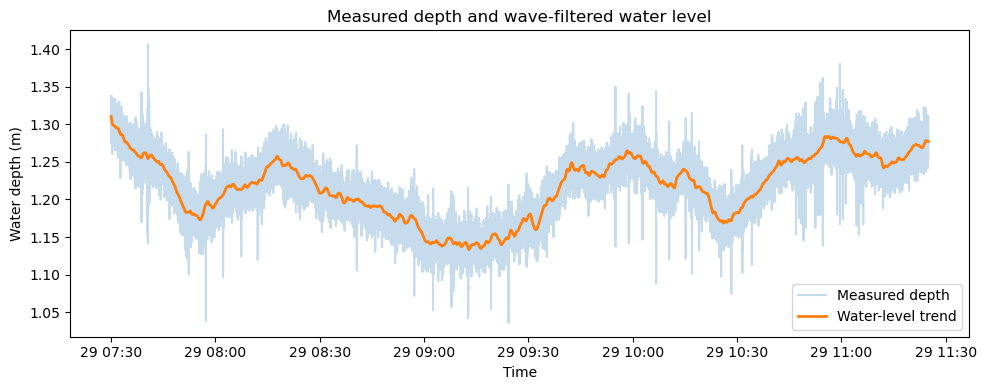

In [14]:
plt.figure(figsize=(10, 4))
plt.plot(time_segment, depth_segment, alpha=0.25, label="Measured depth")
plt.plot(time_segment, water_level_trend, linewidth=2, label="Water-level trend")
plt.xlabel("Time")
plt.ylabel("Water depth (m)")
plt.title("Measured depth and wave-filtered water level")
plt.legend()
plt.tight_layout()
plt.show()

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=cb8feeb3-afee-4b20-ab89-f0abd9348b44' target="_blank">

Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>